In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))
import numpy as np, sympy as sp
from IPython.display import Image, display, Markdown
sp.init_printing(use_unicode=True)
def show(path):
    p = path[0] if isinstance(path, tuple) else path
    display(Image(filename=p))


# 13. Numerical convergence

Tolerance study, solver comparison, fixed-step RK4 order of convergence (expected 4), and a 30-digit mpmath cross-check of the double-precision solver.

In [2]:
from desitter_perturbations.dynamics import convergence as cv
for r in cv.tolerance_study(): print(f"rtol {r['rtol']:.0e}  max err {r['max_err']:.2e}  nfev {r['nfev']}")
h, e, p = cv.rk4_order_study(); print("RK4 observed order:", round(p, 3))
for r in cv.method_comparison(): print(f"{r['method']:7s} err {r['max_err']:.2e}  nfev {r['nfev']:6d}  ok {r['success']}")

rtol 1e-04  max err 8.53e-04  nfev 1046
rtol 1e-06  max err 8.41e-06  nfev 1772
rtol 1e-08  max err 8.13e-08  nfev 3149
rtol 1e-10  max err 7.61e-10  nfev 5381
rtol 1e-12  max err 7.30e-12  nfev 8924


RK4 observed order: 4.003


RK45    err 1.19e-07  nfev   8540  ok True
RK23    err 7.84e-07  nfev  64490  ok True
DOP853  err 8.13e-08  nfev   3149  ok True
Radau   err 1.14e-09  nfev  25603  ok True
BDF     err 4.70e-06  nfev   4751  ok True
LSODA   err 3.24e-07  nfev   3393  ok True


In [3]:
from desitter_perturbations.dynamics.numerical_solvers import solve_mode, solve_mode_mpmath, SolverConfig
xe, g_mp = solve_mode_mpmath(1.0, 10.0, 0.1, dps=30)
s = solve_mode(1.0, 10.0, 0.1, "conformal", SolverConfig(rtol=1e-12, atol=1e-15, n_out=3))
print("mpmath:", g_mp); print("DOP853:", s.gamma[-1]); print("relative difference:", abs(s.gamma[-1]-g_mp)/abs(g_mp))

mpmath: (-0.00033300011902557576+1.0049875069427086j)
DOP853: (-0.0003330001191403093+1.0049875069429433j)
relative difference: 2.5994746364964223e-13


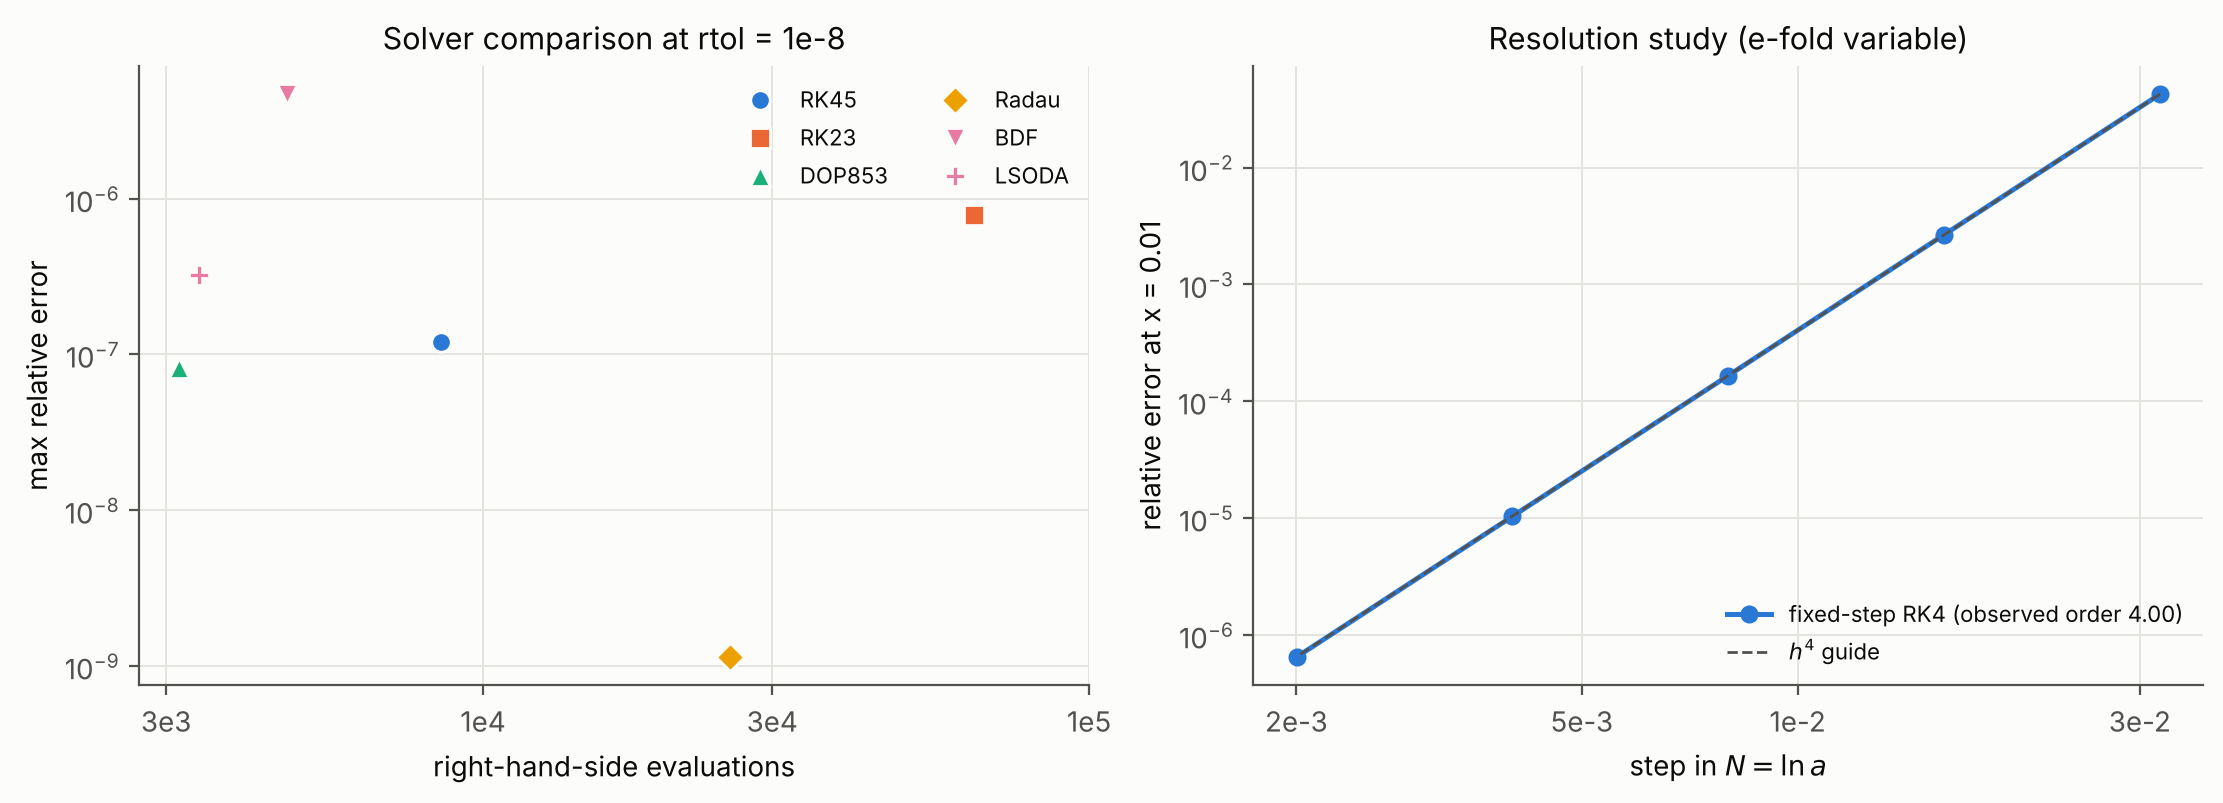

In [4]:
from desitter_perturbations.visualization import convergence_plots as cp
show(cp.plot_methods_and_order())